In [2]:
import pandas as pd
import numpy as np

url = "https://raw.githubusercontent.com/anvarnarz/praktikum_datasets/main/diabetes.csv"
df = pd.read_csv(url)

print(df.shape)
print(df.head())
df.info()
print(df.describe())

# Outcome balansi
print(df["Outcome"].value_counts())

# Yashirin yetishmayotgan qiymatlar (0 lar soni)
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print((df[cols] == 0).sum())

(768, 9)
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose             

In [3]:
# 0 qiymatlarni NaN ga aylantirish
df[cols] = df[cols].replace(0, np.nan)

# Median bilan to'ldirish
df[cols] = df[cols].fillna(df[cols].median())

# Tekshirish
print(df.isnull().sum())
print((df[cols] == 0).sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


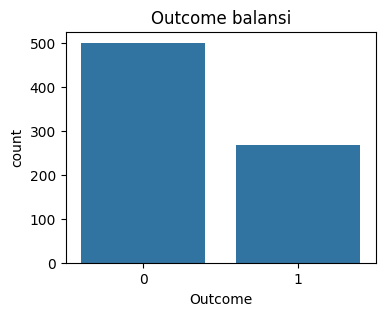

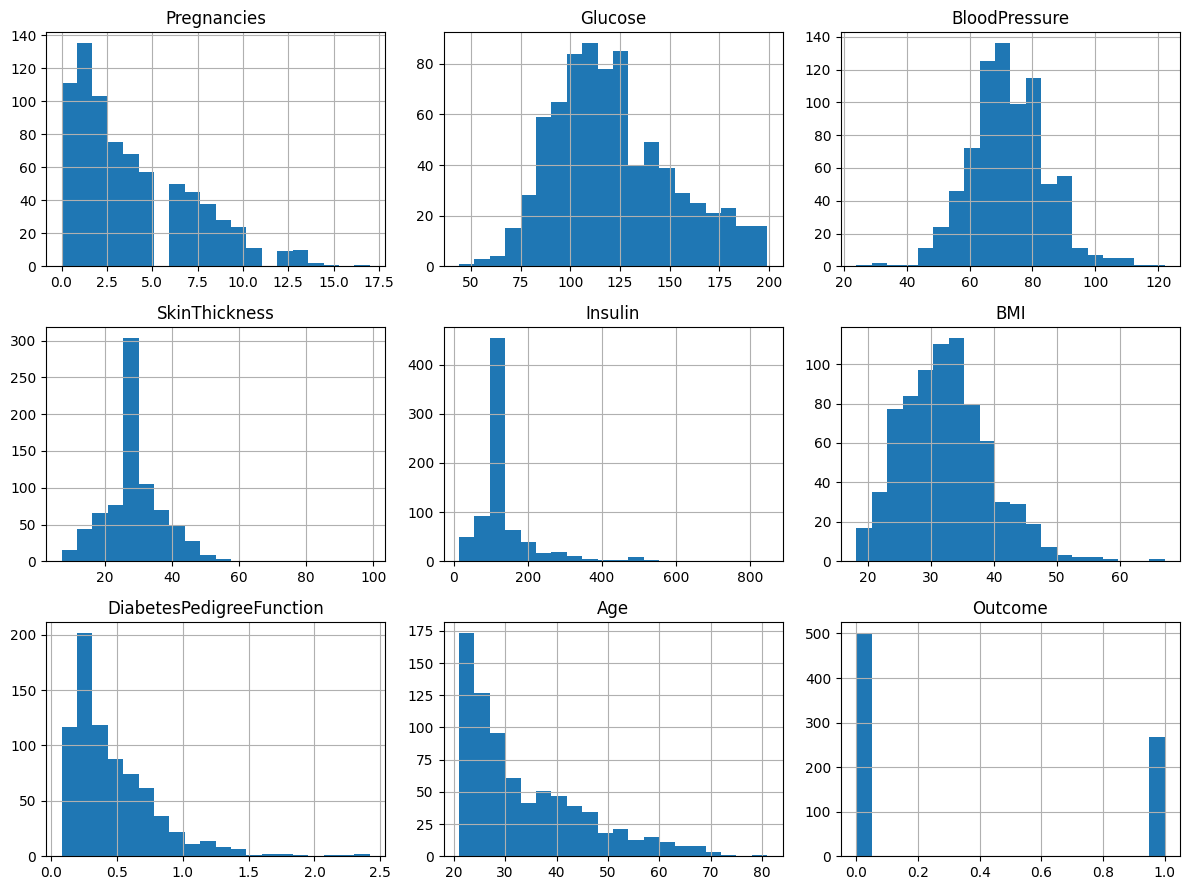

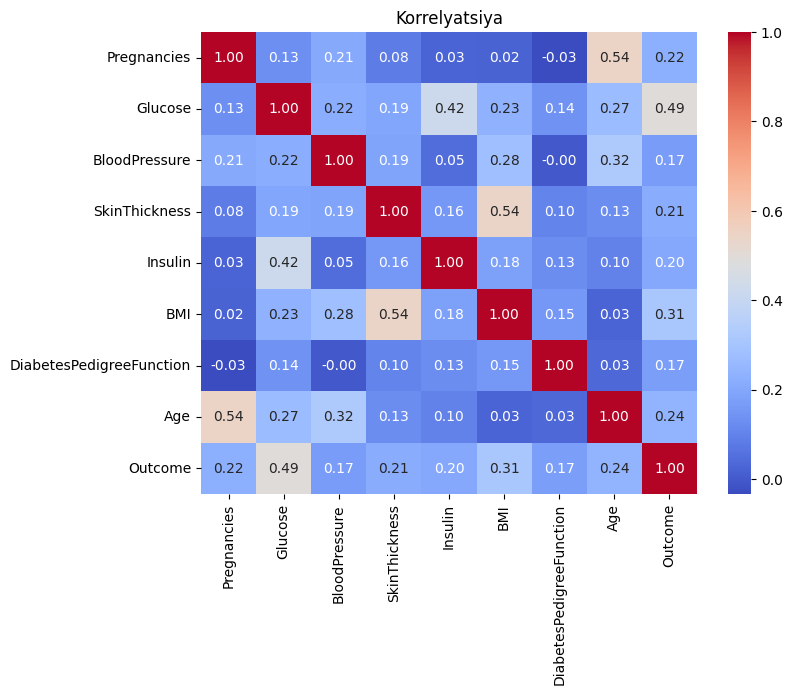

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Outcome balansi
plt.figure(figsize=(4, 3))
sns.countplot(x="Outcome", data=df)
plt.title("Outcome balansi")
plt.show()

# 2. Taqsimotlar (gistogrammalar)
df.hist(figsize=(12, 9), bins=20)
plt.tight_layout()
plt.show()

# 3. Korrelyatsiya xaritasi
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Korrelyatsiya")
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# stratify: ikkala bo'lakda ham sinf nisbati saqlanadi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Masshtablash (faqat train'ga fit qilamiz)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
}

for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    print("=" * 40)
    print(name)
    print(confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred))

Logistic Regression
[[82 18]
 [27 27]]
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154

kNN
[[83 17]
 [21 33]]
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154

Random Forest
[[84 16]
 [24 30]]
              precision    recall  f1-score   support

           0       0.78      0.84      0.81       100
           1       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70

In [6]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models2 = {
    "LogReg": LogisticRegression(max_iter=1000),
    "LogReg (balanced)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "kNN": KNeighborsClassifier(n_neighbors=5),
    "RF": RandomForestClassifier(n_estimators=200, random_state=42),
    "RF (balanced)": RandomForestClassifier(n_estimators=200, random_state=42, class_weight="balanced"),
}

for name, m in models2.items():
    pipe = make_pipeline(StandardScaler(), m)
    acc = cross_val_score(pipe, X, y, cv=cv, scoring="accuracy").mean()
    rec = cross_val_score(pipe, X, y, cv=cv, scoring="recall").mean()
    print(f"{name:20s} accuracy={acc:.3f}  recall={rec:.3f}")

LogReg               accuracy=0.773  recall=0.571
LogReg (balanced)    accuracy=0.747  recall=0.727
kNN                  accuracy=0.724  recall=0.571
RF                   accuracy=0.762  recall=0.604
RF (balanced)        accuracy=0.762  recall=0.593


In [7]:
final = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, class_weight="balanced")
)
final.fit(X_train, y_train)
pred = final.predict(X_test)

print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

# Qaysi belgilar eng muhim (koeffitsiyentlar)
coefs = pd.Series(final[-1].coef_[0], index=X.columns).sort_values(ascending=False)
print(coefs)

[[75 25]
 [16 38]]
              precision    recall  f1-score   support

           0       0.82      0.75      0.79       100
           1       0.60      0.70      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.72       154
weighted avg       0.75      0.73      0.74       154

Glucose                     1.183444
BMI                         0.709709
Pregnancies                 0.373019
DiabetesPedigreeFunction    0.287745
Age                         0.186393
SkinThickness               0.013877
BloodPressure              -0.014548
Insulin                    -0.044651
dtype: float64


**Loyiha:** Pima Indians datasetida diabetni bashorat qilish (768 bemor, 8 belgi).

**Tozalash:** Glucose, BloodPressure, SkinThickness, Insulin va BMI ustunlaridagi 0 qiymatlar yetishmayotgan ma'lumot deb hisoblanib, median bilan to'ldirildi.

**Modellar:** Logistic Regression, kNN va Random Forest 5-fold stratified cross-validation bilan solishtirildi. Tibbiy skrining vazifasida kasalni o'tkazib yuborish qimmat bo'lgani uchun asosiy metrika sifatida recall tanlandi.

**Natija:** class_weight="balanced" bilan Logistic Regression recall'ni 0.57 dan 0.73 gacha oshirdi (accuracy 0.77 dan 0.75 ga tushdi). Test to'plamida: accuracy 0.73, diabet sinfi uchun recall 0.70, precision 0.60.

**Xulosa:** Eng muhim belgilar Glucose va BMI. Bitta train/test bo'linishida kNN yaxshi ko'ringan bo'lsa-da, cross-validation uni eng zaif model ekanini ko'rsatdi, shuning uchun bitta bo'linishga tayanib xulosa qilmaslik kerak.

**Cheklov:** Dataset kichik va faqat 21 yoshdan oshgan ayollardan iborat, shuning uchun model boshqa guruhlarga umumlashtirilmaydi. Model tibbiy tashxis emas, faqat o'quv loyihasi.